Train rows: 413 | Test rows: 103 | Total: 516
     id_code  dr_grade  dme_risk  split
0  IDRiD_001         3         2  train
1  IDRiD_002         3         2  train
2  IDRiD_003         2         2  train
3  IDRiD_004         3         2  train
4  IDRiD_005         4         0  train

Images found — train folder: 413 | test folder: 103

[train] Labeled IDs with no matching image file: 0
[train] Image files with no matching label row: 0

[test] Labeled IDs with no matching image file: 0
[test] Image files with no matching label row: 0

DR grade distribution (overall):
  Grade 0 (No DR): 168 images (32.6%)
  Grade 1 (Mild): 25 images (4.8%)
  Grade 2 (Moderate): 168 images (32.6%)
  Grade 3 (Severe): 93 images (18.0%)
  Grade 4 (Proliferative DR): 62 images (12.0%)

DR grade distribution by split:
split     test  train
dr_grade             
0           34    134
1            5     20
2           32    136
3           19     74
4           13     49

DME risk distribution (overall):
  Ri

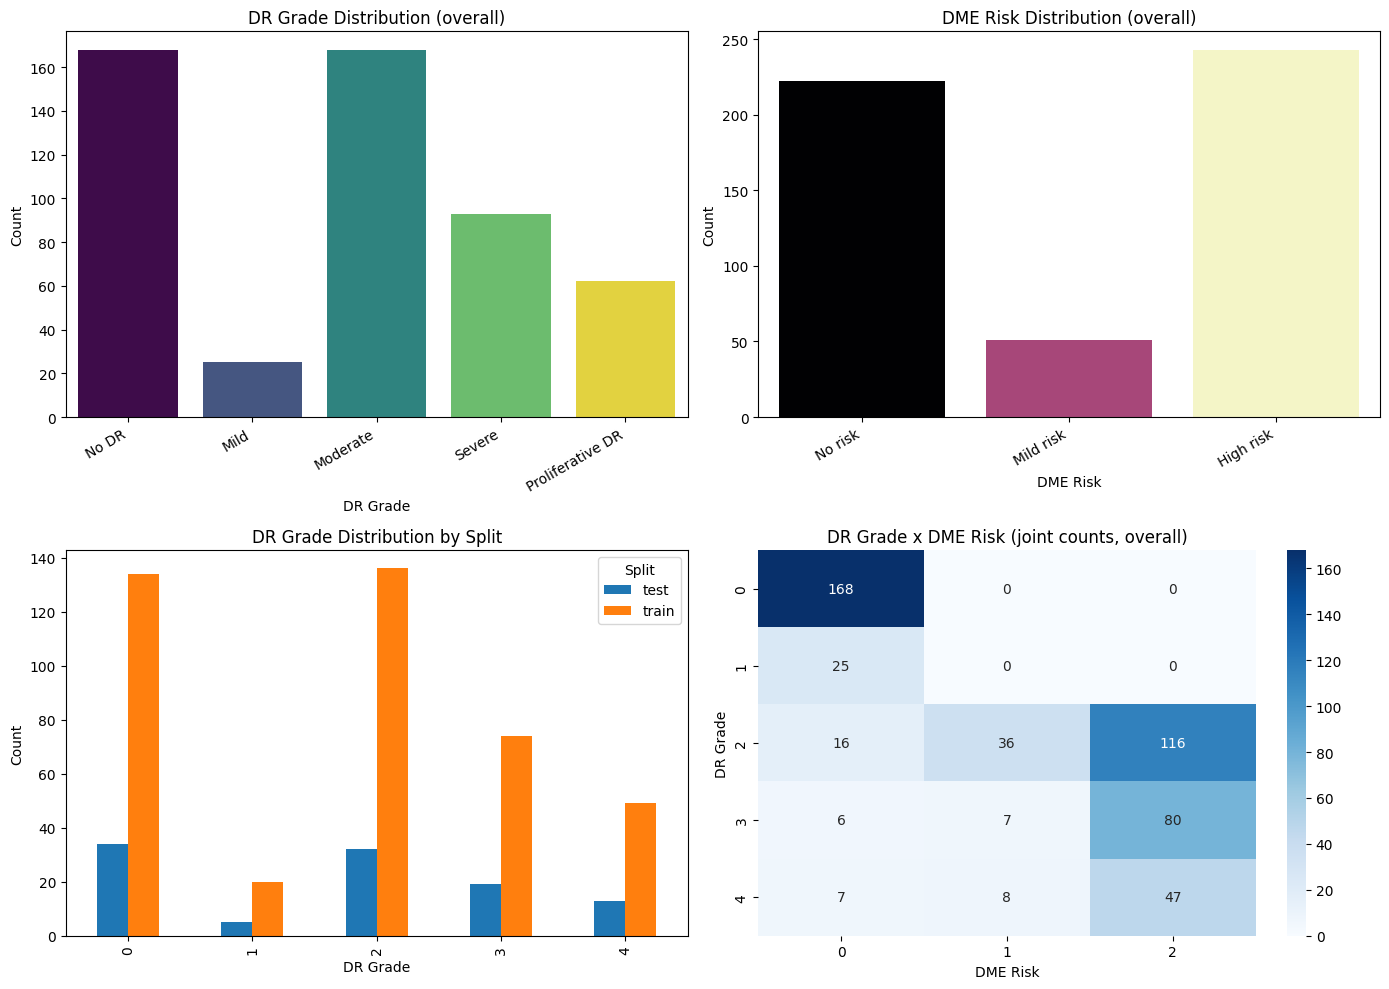


DR class imbalance ratio (majority:minority) = 6.72 : 1
DME class imbalance ratio = 4.76:1
Saved merged/cleaned labels to idrid_labels_merged.csv


In [1]:
"""
IDRiD Dataset — Distribution & Sanity-Check Analysis
------------------------------------------------------
Handles the official "B. Disease Grading" folder structure, which has
SEPARATE train and test image folders and SEPARATE train and test label CSVs:

    B. Disease Grading/
    ├── 1. Original Images/
    │   ├── a. Training Set/        (413 .jpg images)
    │   └── b. Testing Set/         (103 .jpg images)
    └── 2. Groundtruth/
        ├── a. IDRiD_Disease Grading_Training Labels.csv
        └── b. IDRiD_Disease Grading_Testing Labels.csv

Loads both splits, merges them with a `split` column so you can either
respect the official train/test split (recommended, comparable to other
papers) or pool everything and do your own split later.

Update the paths below to match your local folder after extraction.
"""

import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ---------------------------------------------------------------
# 1. Paths — EDIT THESE to match your extracted folder
# ---------------------------------------------------------------
BASE_DIR = r"D:\B. Disease Grading"

TRAIN_IMG_DIR = os.path.join(BASE_DIR, "1. Original Images", "a. Training Set")
TEST_IMG_DIR  = os.path.join(BASE_DIR, "1. Original Images", "b. Testing Set")

TRAIN_CSV = os.path.join(BASE_DIR, "2. Groundtruths", "a. IDRiD_Disease Grading_Training Labels.csv")
TEST_CSV  = os.path.join(BASE_DIR, "2. Groundtruths", "b. IDRiD_Disease Grading_Testing Labels.csv")

# DR grade / DME risk label meanings (per IDRiD documentation)
DR_LABELS = {
    0: "No DR",
    1: "Mild",
    2: "Moderate",
    3: "Severe",
    4: "Proliferative DR",
}
DME_LABELS = {
    0: "No risk",
    1: "Mild risk",
    2: "High risk",
}


def load_labels(csv_path: str, split_name: str) -> pd.DataFrame:
    """Load one split's label CSV, clean it, and tag it with split_name."""
    if not os.path.isfile(csv_path):
        print(f"[!] CSV not found: {csv_path}")
        return pd.DataFrame(columns=["id_code", "dr_grade", "dme_risk", "split"])

    df = pd.read_csv(csv_path)
    df.columns = [c.strip() for c in df.columns]

    # Drop stray "Unnamed: N" columns from trailing commas in the CSV export
    df = df.loc[:, ~df.columns.str.startswith("Unnamed")]

    # Column names in the official CSVs are typically:
    # "Image name", "Retinopathy grade", "Risk of macular edema"
    # — rename flexibly in case yours differ slightly.
    rename_map = {}
    for col in df.columns:
        low = col.lower()
        if "image" in low or col == "id_code":
            rename_map[col] = "id_code"
        elif "retinopathy" in low or col == "diagnosis":
            rename_map[col] = "dr_grade"
        elif "macular" in low or col == "dme_risk":
            rename_map[col] = "dme_risk"
    df = df.rename(columns=rename_map)

    df = df.dropna(subset=["id_code"]).reset_index(drop=True)
    df["id_code"] = df["id_code"].astype(str).str.strip()
    df["dr_grade"] = df["dr_grade"].astype(int)
    df["dme_risk"] = df["dme_risk"].astype(int)
    df["split"] = split_name
    return df


def list_images(img_dir: str) -> set:
    """Return the set of image IDs (no extension) found in a folder."""
    if not os.path.isdir(img_dir):
        print(f"[!] Image folder not found: {img_dir}")
        return set()
    return {os.path.splitext(f)[0] for f in os.listdir(img_dir)
            if f.lower().endswith((".jpg", ".jpeg", ".png"))}


# ---------------------------------------------------------------
# 2. Load both splits and merge
# ---------------------------------------------------------------
train_df = load_labels(TRAIN_CSV, "train")
test_df  = load_labels(TEST_CSV, "test")

df = pd.concat([train_df, test_df], ignore_index=True)
print(f"Train rows: {len(train_df)} | Test rows: {len(test_df)} | Total: {len(df)}")
print(df.head())

# ---------------------------------------------------------------
# 3. Cross-check labels against actual image files, per split
# ---------------------------------------------------------------
train_files = list_images(TRAIN_IMG_DIR)
test_files  = list_images(TEST_IMG_DIR)
print(f"\nImages found — train folder: {len(train_files)} | test folder: {len(test_files)}")

for split_name, label_ids, files_on_disk in [
    ("train", set(train_df["id_code"]), train_files),
    ("test",  set(test_df["id_code"]),  test_files),
]:
    missing_images = label_ids - files_on_disk
    unlabeled_images = files_on_disk - label_ids
    print(f"\n[{split_name}] Labeled IDs with no matching image file: {len(missing_images)}")
    if missing_images:
        print("  e.g.", list(missing_images)[:10])
    print(f"[{split_name}] Image files with no matching label row: {len(unlabeled_images)}")
    if unlabeled_images:
        print("  e.g.", list(unlabeled_images)[:10])

# ---------------------------------------------------------------
# 4. Class distribution — DR grade (overall + per split)
# ---------------------------------------------------------------
dr_counts = df["dr_grade"].value_counts().sort_index()
print("\nDR grade distribution (overall):")
for grade, count in dr_counts.items():
    label = DR_LABELS.get(grade, f"Unknown ({grade})")
    pct = 100 * count / len(df)
    print(f"  Grade {grade} ({label}): {count} images ({pct:.1f}%)")

print("\nDR grade distribution by split:")
print(pd.crosstab(df["dr_grade"], df["split"]))

# ---------------------------------------------------------------
# 5. Class distribution — DME risk (overall + per split)
# ---------------------------------------------------------------
dme_counts = df["dme_risk"].value_counts().sort_index()
print("\nDME risk distribution (overall):")
for risk, count in dme_counts.items():
    label = DME_LABELS.get(risk, f"Unknown ({risk})")
    pct = 100 * count / len(df)
    print(f"  Risk {risk} ({label}): {count} images ({pct:.1f}%)")

print("\nDME risk distribution by split:")
print(pd.crosstab(df["dme_risk"], df["split"]))

# ---------------------------------------------------------------
# 6. Joint distribution (DR grade x DME risk)
# ---------------------------------------------------------------
joint = pd.crosstab(df["dr_grade"], df["dme_risk"])
print("\nJoint DR grade x DME risk counts (overall):")
print(joint)

# ---------------------------------------------------------------
# 7. Plots
# ---------------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

dr_tick_labels = [DR_LABELS.get(i, i) for i in dr_counts.index]
sns.barplot(x=list(dr_counts.index), y=dr_counts.values, hue=list(dr_counts.index),
            palette="viridis", legend=False, ax=axes[0, 0])
axes[0, 0].set_title("DR Grade Distribution (overall)")
axes[0, 0].set_xlabel("DR Grade")
axes[0, 0].set_ylabel("Count")
axes[0, 0].set_xticks(range(len(dr_tick_labels)))
axes[0, 0].set_xticklabels(dr_tick_labels, rotation=30, ha="right")

dme_tick_labels = [DME_LABELS.get(i, i) for i in dme_counts.index]
sns.barplot(x=list(dme_counts.index), y=dme_counts.values, hue=list(dme_counts.index),
            palette="magma", legend=False, ax=axes[0, 1])
axes[0, 1].set_title("DME Risk Distribution (overall)")
axes[0, 1].set_xlabel("DME Risk")
axes[0, 1].set_ylabel("Count")
axes[0, 1].set_xticks(range(len(dme_tick_labels)))
axes[0, 1].set_xticklabels(dme_tick_labels, rotation=30, ha="right")

# DR grade distribution split by train/test — check the split is stratified
dr_split_ct = pd.crosstab(df["dr_grade"], df["split"])
dr_split_ct.plot(kind="bar", ax=axes[1, 0])
axes[1, 0].set_title("DR Grade Distribution by Split")
axes[1, 0].set_xlabel("DR Grade")
axes[1, 0].set_ylabel("Count")
axes[1, 0].legend(title="Split")

sns.heatmap(joint, annot=True, fmt="d", cmap="Blues", ax=axes[1, 1])
axes[1, 1].set_title("DR Grade x DME Risk (joint counts, overall)")
axes[1, 1].set_xlabel("DME Risk")
axes[1, 1].set_ylabel("DR Grade")

plt.tight_layout()
plt.savefig("idrid_distribution.png", dpi=150)
print("\nSaved plot to idrid_distribution.png")
plt.show()

# ---------------------------------------------------------------
# 8. Class imbalance ratio — worth reporting in your methodology
# ---------------------------------------------------------------
majority = dr_counts.max()
minority = dr_counts.min()
print(f"\nDR class imbalance ratio (majority:minority) = {majority / minority:.2f} : 1")
dme_majority = dme_counts.max()
dme_minority = dme_counts.min()

print(
    f"DME class imbalance ratio = "
    f"{dme_majority / dme_minority:.2f}:1"
)
# ---------------------------------------------------------------
# 9. Save merged, cleaned label table for downstream use
# ---------------------------------------------------------------
df.to_csv("idrid_labels_merged.csv", index=False)
print("Saved merged/cleaned labels to idrid_labels_merged.csv")

Loaded 516 labeled rows
Saved sample_images_dr_grades.png


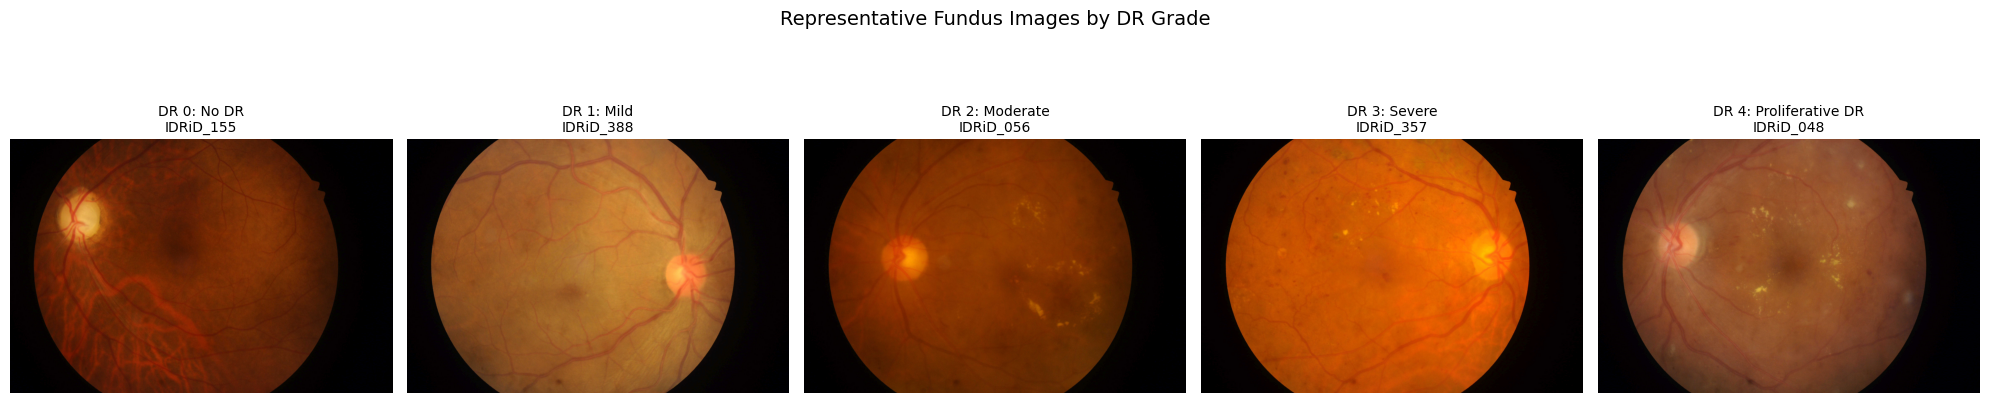

Saved sample_images_dme_risk.png


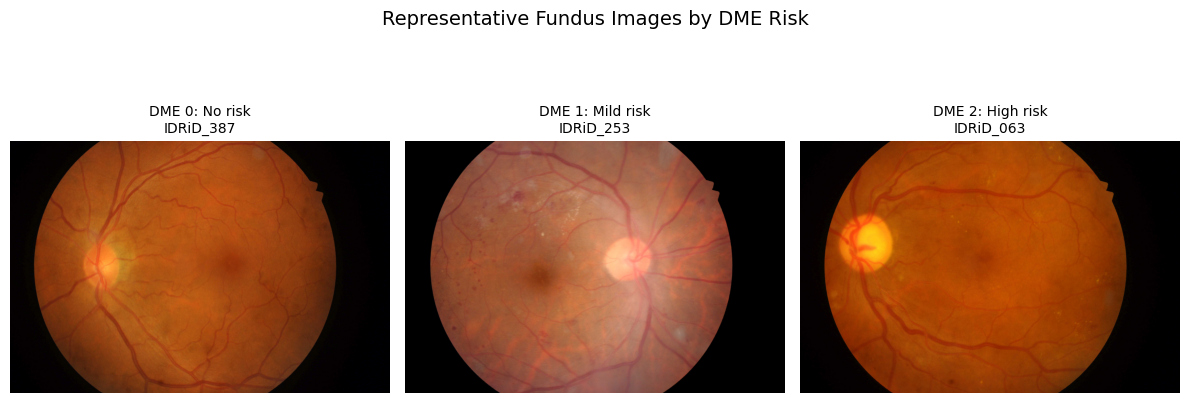

Saved sample_images_dr_grades_grid.png


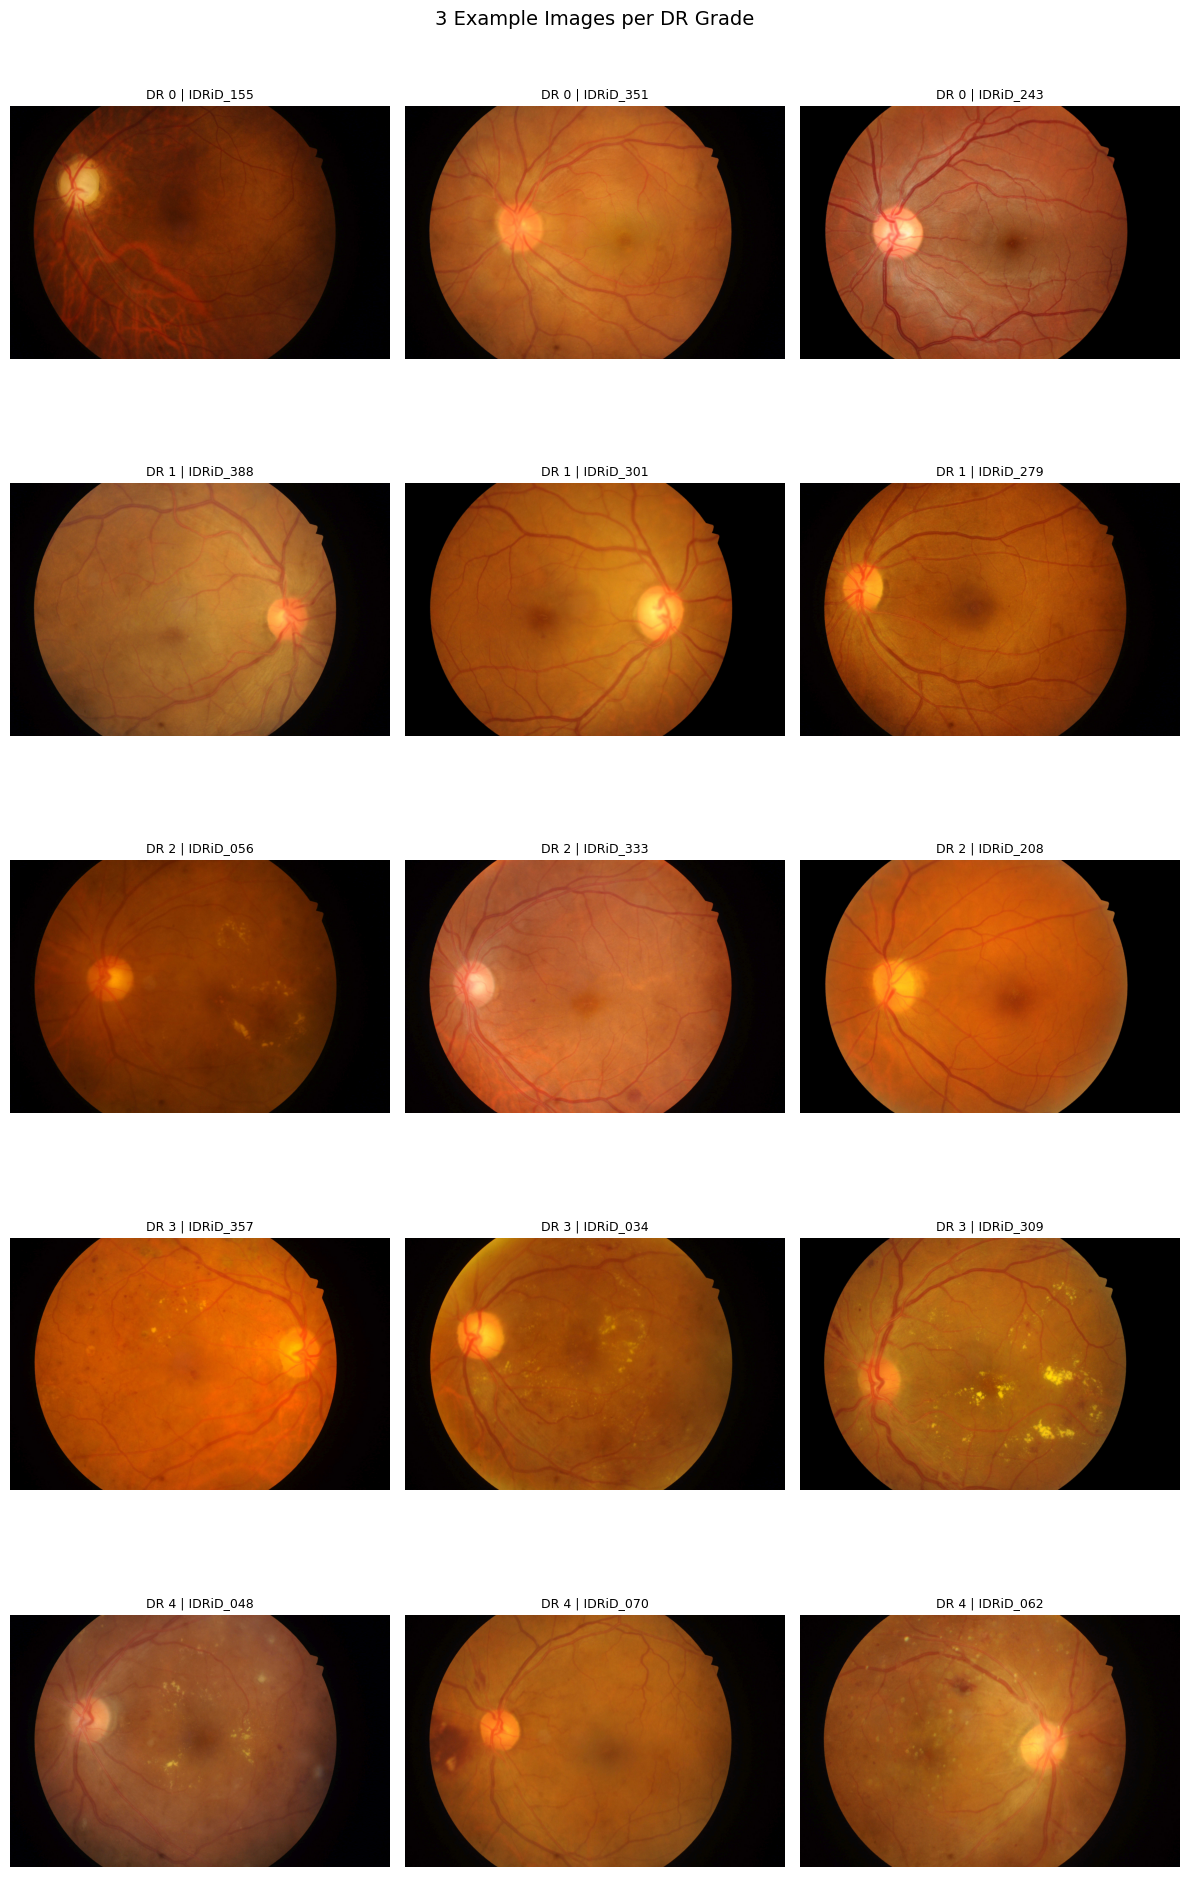

In [2]:
"""
IDRiD — Sample Fundus Image Visualization
------------------------------------------
Shows representative fundus images for each DR grade (0-4) and each
DME risk level (0-2), using the merged label table produced by
idrid_distribution_analysis.py (idrid_labels_merged.csv).

Assumes:
  - idrid_labels_merged.csv exists (has columns: id_code, dr_grade, dme_risk, split)
  - TRAIN_IMG_DIR / TEST_IMG_DIR point to the folders with the .jpg files
  - Images may live in either the train or test folder — this script
    checks both since the merged CSV mixes both splits.
"""

import os
import random
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# ---------------------------------------------------------------
# 1. Paths — EDIT THESE to match your setup
# ---------------------------------------------------------------
MERGED_CSV = "idrid_labels_merged.csv"   # produced by the earlier script

BASE_DIR = r"D:\B. Disease Grading"
TRAIN_IMG_DIR = os.path.join(BASE_DIR, "1. Original Images", "a. Training Set")
TEST_IMG_DIR  = os.path.join(BASE_DIR, "1. Original Images", "b. Testing Set")

DR_LABELS = {0: "No DR", 1: "Mild", 2: "Moderate", 3: "Severe", 4: "Proliferative DR"}
DME_LABELS = {0: "No risk", 1: "Mild risk", 2: "High risk"}

RANDOM_SEED = 42  # set to None for a different random sample each run

# ---------------------------------------------------------------
# 2. Load merged labels
# ---------------------------------------------------------------
df = pd.read_csv(MERGED_CSV)
print(f"Loaded {len(df)} labeled rows")


def find_image_path(id_code: str):
    """Look for id_code.jpg in either the train or test folder."""
    for folder in (TRAIN_IMG_DIR, TEST_IMG_DIR):
        candidate = os.path.join(folder, f"{id_code}.jpg")
        if os.path.isfile(candidate):
            return candidate
    return None


def get_sample_for_class(df: pd.DataFrame, column: str, value: int, seed=None):
    """Pick one random id_code with the given label value that has a
    findable image file on disk. Returns (id_code, path) or (None, None)."""
    subset = df[df[column] == value]["id_code"].tolist()
    if seed is not None:
        random.Random(seed).shuffle(subset)
    else:
        random.shuffle(subset)
    for id_code in subset:
        path = find_image_path(id_code)
        if path:
            return id_code, path
    return None, None


# ---------------------------------------------------------------
# 3. Plot one representative image per DR grade
# ---------------------------------------------------------------
dr_grades = sorted(DR_LABELS.keys())
fig, axes = plt.subplots(1, len(dr_grades), figsize=(4 * len(dr_grades), 5))

for ax, grade in zip(axes, dr_grades):
    id_code, path = get_sample_for_class(df, "dr_grade", grade, seed=RANDOM_SEED)
    if path:
        img = Image.open(path)
        ax.imshow(img)
        ax.set_title(f"DR {grade}: {DR_LABELS[grade]}\n{id_code}", fontsize=10)
    else:
        ax.text(0.5, 0.5, f"No image found\nfor DR grade {grade}",
                 ha="center", va="center")
    ax.axis("off")

plt.suptitle("Representative Fundus Images by DR Grade", fontsize=14)
plt.tight_layout()
plt.savefig("sample_images_dr_grades.png", dpi=150)
print("Saved sample_images_dr_grades.png")
plt.show()

# ---------------------------------------------------------------
# 4. Plot one representative image per DME risk level
# ---------------------------------------------------------------
dme_risks = sorted(DME_LABELS.keys())
fig, axes = plt.subplots(1, len(dme_risks), figsize=(4 * len(dme_risks), 5))

for ax, risk in zip(axes, dme_risks):
    id_code, path = get_sample_for_class(df, "dme_risk", risk, seed=RANDOM_SEED)
    if path:
        img = Image.open(path)
        ax.imshow(img)
        ax.set_title(f"DME {risk}: {DME_LABELS[risk]}\n{id_code}", fontsize=10)
    else:
        ax.text(0.5, 0.5, f"No image found\nfor DME risk {risk}",
                 ha="center", va="center")
    ax.axis("off")

plt.suptitle("Representative Fundus Images by DME Risk", fontsize=14)
plt.tight_layout()
plt.savefig("sample_images_dme_risk.png", dpi=150)
print("Saved sample_images_dme_risk.png")
plt.show()

# ---------------------------------------------------------------
# 5. Optional: grid of MULTIPLE examples per DR grade (e.g. 3 each)
#    Useful to see within-class visual variation, not just one example.
# ---------------------------------------------------------------
N_PER_CLASS = 3
fig, axes = plt.subplots(len(dr_grades), N_PER_CLASS,
                          figsize=(4 * N_PER_CLASS, 4 * len(dr_grades)))

for row, grade in enumerate(dr_grades):
    subset = df[df["dr_grade"] == grade]["id_code"].tolist()
    rng = random.Random(RANDOM_SEED)
    rng.shuffle(subset)

    found = 0
    for id_code in subset:
        if found >= N_PER_CLASS:
            break
        path = find_image_path(id_code)
        if not path:
            continue
        ax = axes[row, found]
        img = Image.open(path)
        ax.imshow(img)
        ax.set_title(f"DR {grade} | {id_code}", fontsize=9)
        ax.axis("off")
        found += 1

    # blank out any unused cells in this row
    for col in range(found, N_PER_CLASS):
        axes[row, col].axis("off")

plt.suptitle(f"{N_PER_CLASS} Example Images per DR Grade", fontsize=14)
plt.tight_layout()
plt.savefig("sample_images_dr_grades_grid.png", dpi=150)
print("Saved sample_images_dr_grades_grid.png")
plt.show()